# **Support Vector Machines (SVM)**



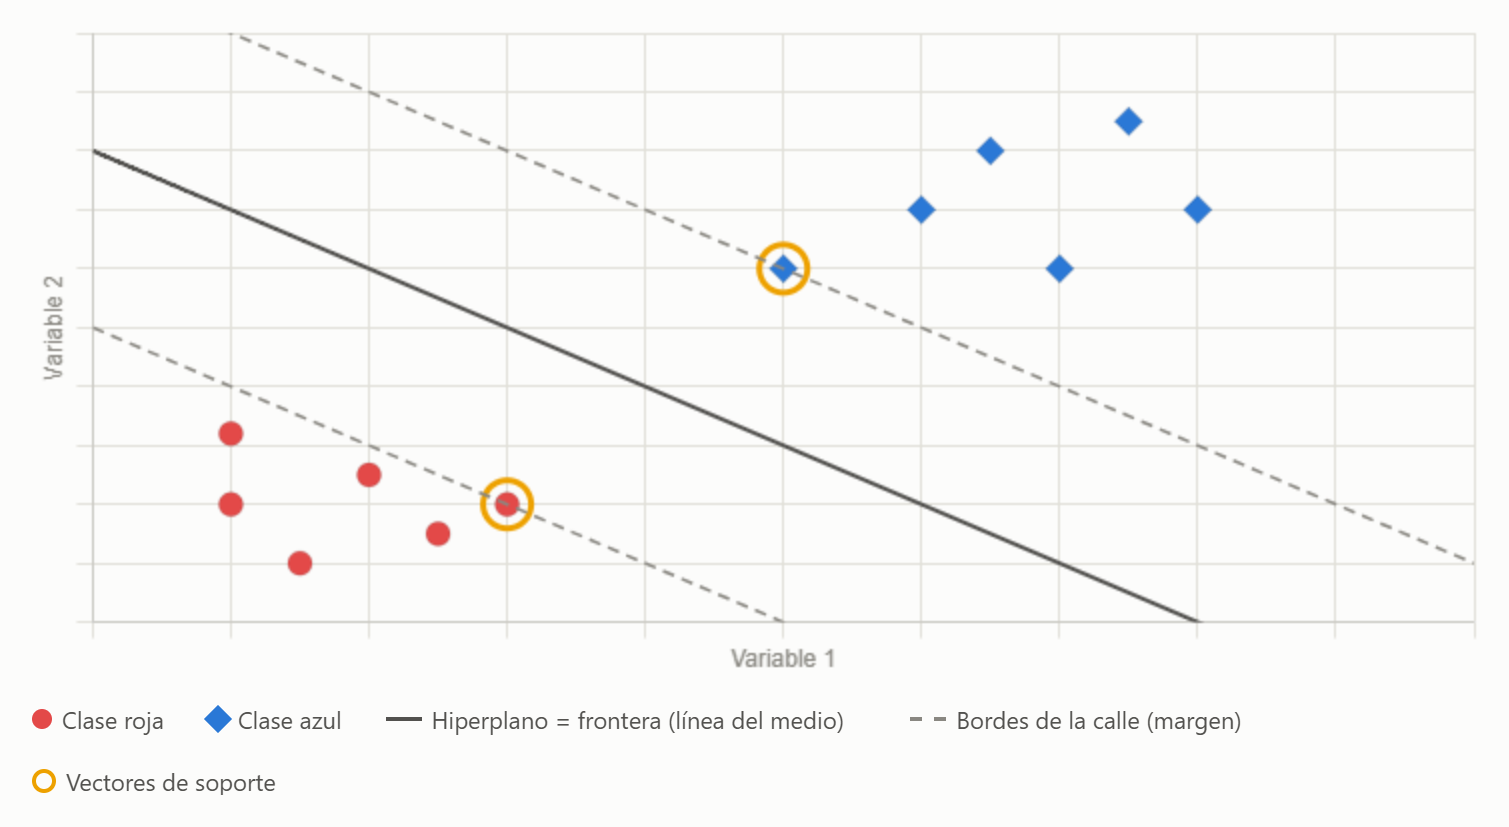

Es una técnica o modelo que se utiliza para la clasificación principalmente pero también para la regresión.

- **Hiperplano** = frontera de decisión: es la línea del medio de la calle (la línea gris continua). Es la que decide: de un lado, rojo; del otro, azul. Hiperplano y frontera sí son lo mismo.

- **Margen**: es el ancho de la calle, la distancia entre la línea del medio y los bordes (las líneas punteadas). SVM busca que sea lo más ancho posible.

- **Vectores de soporte**: son los puntos que quedan justo sobre los bordes de la calle (los marcados con un círculo amarillo). Son los más cercanos a la frontera.

Lo curioso de los **vectores de soporte**: la calle depende solo de ellos. Si movés cualquier otro punto lejano, la calle no cambia. Si movés un vector de soporte, la calle se mueve. Por eso el modelo se llama así: esos puntos “sostienen” la calle.


**Truco de kernal:** Cuando los datos no son separables con una recta, SVM aplica el truco del kernel: trabaja como si los datos estuvieran en un espacio de más dimensiones, donde sí se pueden separar con un hiperplano, pero sin calcular esas dimensiones de forma explícita. En el espacio original, esa frontera se ve curva. El kernel es un hiperparámetro: lo elegís vos, antes de entrenar, igual que α en el descenso por gradiente.

**Tipos de kernel en SVM**

| Kernel | Forma de la frontera | Cuándo sirve | Observaciones |
|---|---|---|---|
| **Lineal** | Recta (hiperplano) | Datos que ya se separan con una línea | El más simple. Hiperparámetro: C |
| **Polinomial** | Curva suave, con cierto grado de curvatura | Fronteras curvas suaves | Depende mucho del grado: si es incorrecto, puede rendir peor que RBF o que el lineal |
| **RBF (radial)** | Curvas muy flexibles: círculos, islas, formas irregulares | Patrones circulares, espirales o complejos | El más usado. Hiperparámetros: C y gamma |
| **Sigmoide** | Curvas segmentadas o irregulares | Poco usado en la práctica | Puede dar fronteras inconsistentes y ajustarse al ruido (sobreajuste) |

> A partir de los kernels no lineales, SVM puede tener límites de decisión no lineales (diapo 26).

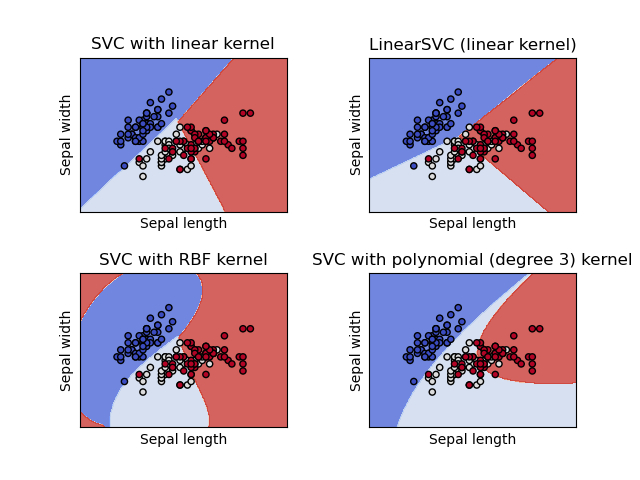

**flujo, ajustado**

- Separar train y test. El test queda guardado.
- Con el train y CV:
SVM lineal: probar varios valores de C y quedarte con el mejor.
SVM RBF: probar varias combinaciones de C y gamma y quedarte con la mejor.
- Comparar el lineal contra el RBF con las métricas de la CV (AUC, accuracy…) y elegir el ganador.
- Reentrenar el ganador con todo el train.
- Evaluar una sola vez en el test: ese resultado es la estimación de cómo va a andar con datos nuevos.

**Flujo blando:** con datos reales, casi nunca hay una calle perfectamente limpia. Siempre hay algunos puntos mezclados: dentro de la calle o del lado equivocado.

Dos opciones

- Margen duro: no se permite ningún punto dentro de la calle. Para lograrlo, la calle tiene que quedar muy angosta y retorcida, esquivando cada punto raro.
- Margen blando: se permiten algunos puntos dentro de la calle o mal clasificados, a cambio de una calle más ancha y simple.

Las **variables de holgura** (ε) miden cuánto viola la calle cada punto, no es un hiperparámetro ni una métrica de evaluación. Es un valor interno que el modelo calcula para cada punto durante el entrenamiento:

ε = 0: bien clasificado y fuera de la calle.
Entre 0 y 1: dentro de la calle, pero del lado correcto.
Mayor a 1: del lado equivocado, mal clasificado.

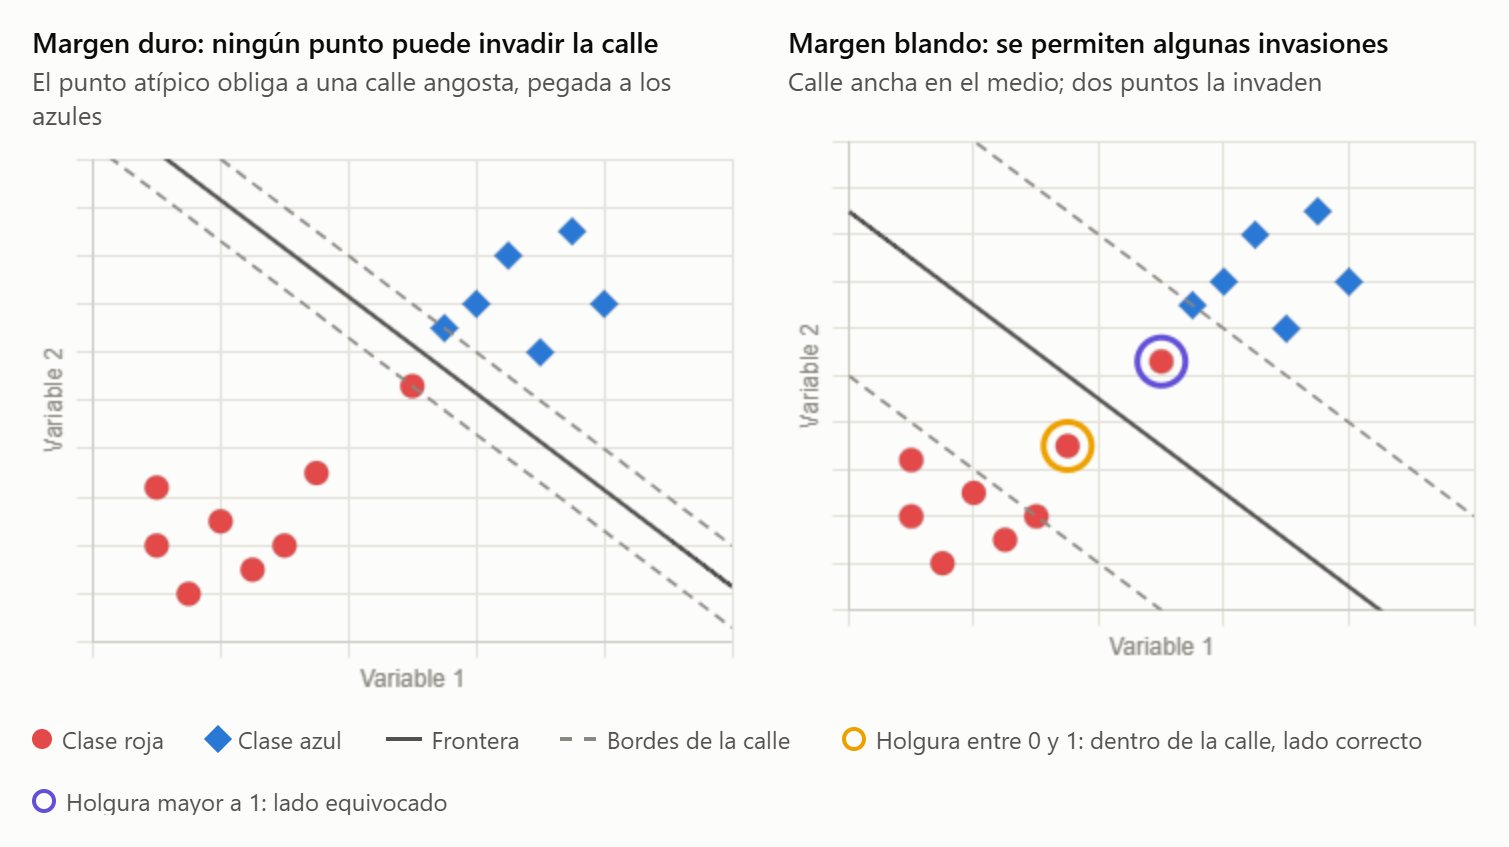

**Hiperparámetro C (`cost`)**

C es el **costo de clasificar mal** un punto de train (margen blando / *soft margin*).

* **C bajo** → al modelo le importa poco equivocarse en algunos puntos → **margen ancho**, frontera más simple → más sesgo, menos varianza.
* **C alto** → castiga mucho cada error → **margen angosto**, la frontera se dobla para acertar todo train → riesgo de **sobreajuste**.

**Hiperparámetro gamma (`rbf_sigma`)**

define hasta dónde llega la influencia de cada punto del train sobre la frontera.

Una analogía: cada punto es una lámpara

Gamma alto: cada lámpara ilumina solo un círculo chiquito a su alrededor. La frontera se arma rodeando cada punto por separado, con “islas” alrededor de cada uno. El modelo se ajusta a detalles individuales, y hay sobreajuste.
Gamma bajo: cada lámpara ilumina una zona amplia. Las luces se mezclan y la frontera queda suave, siguiendo la tendencia general. El modelo generaliza mejor.

### ¿Cómo elegimos kernel, C y gamma?

Con **grid search + validación cruzada**: armamos una grilla de combinaciones, cada combinación se entrena y evalúa en los folds, y nos quedamos con la de mejor métrica **promedio en los folds** (nunca mirando test).

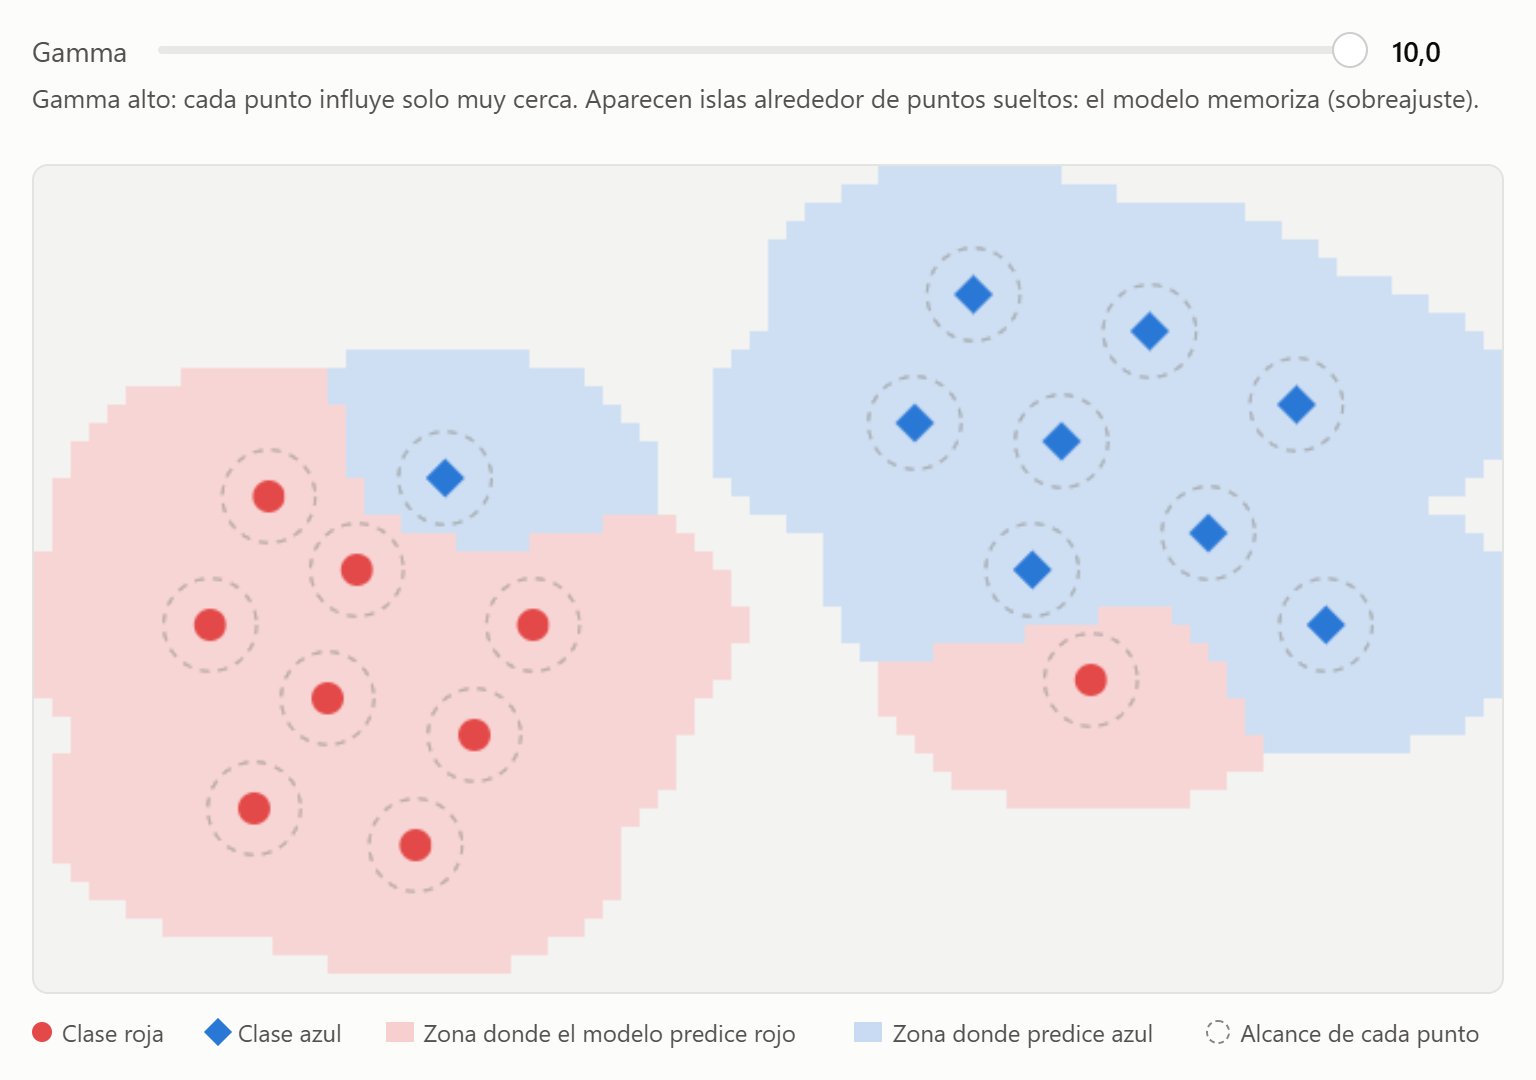

## **Variables del dataset**

Los datos están disponibles en este link: https://github.com/rfordatascience/tidytuesday/blob/master/data/2021/2021-05-04/readme.md

Se ofrece una descripción del dataset además de detallarse los pasos de limpieza que se realizan a la base de datos original. Para una descripción del problema visitar https://www.waterpointdata.org/  

**La variable a predecir es status_id** y nos dice si hay o no disponibles agua, según diferentes variables.

Estas variables son:

* row_id: id

* lat_deg: latitud

* lon_deg: longitud

* report_date: fecha en que se reporto esa fuente de agua.

* status_id: identifica si está disponible esa fuente de agua, el dia de la visita (si/no).
* water_source_clean: describe la fuente de agua (variable categórica)

* water_tech: describe si el sistema utilizado para transportar el agua desde la fuente al punto de recolección (incluye la posibilidad de q sea un distribuidor).

* facility_type:

* country_name: pais

* install_year: año de la instalación

* installer: instalador

* pago: como se realiza el pago.

* status: estado de la condición física / mecánica del punto de agua.

In [ ]:
## Cargamos paquetes
# Binarios precompilados de Posit Package Manager: instala mucho más rápido en Colab.
# kernlab es el motor que usa parsnip para SVM.

os <- readLines("/etc/os-release")
codename <- sub("VERSION_CODENAME=", "", grep("^VERSION_CODENAME=", os, value = TRUE))
options(
  HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
                          paste(getRversion(), R.version$platform, R.version$arch, R.version$os)),
  repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", codename, "/latest")),
  Ncpus = parallel::detectCores()
)

paquetes <- c("tidymodels", "themis", "doParallel", "kernlab")
faltan <- paquetes[!sapply(paquetes, requireNamespace, quietly = TRUE)]
if (length(faltan) > 0) install.packages(faltan)

In [ ]:
# cargamos librerias
suppressPackageStartupMessages({
  library(tidymodels)
  library(tidyverse)
  library(themis)   # para balancear clases (step_downsample)
})

## **Cargar datos**

In [ ]:
## Ingreso el dataset

water_raw <- read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-05-04/water.csv",
                      show_col_types = FALSE)

## **Gráfico exploratorio**

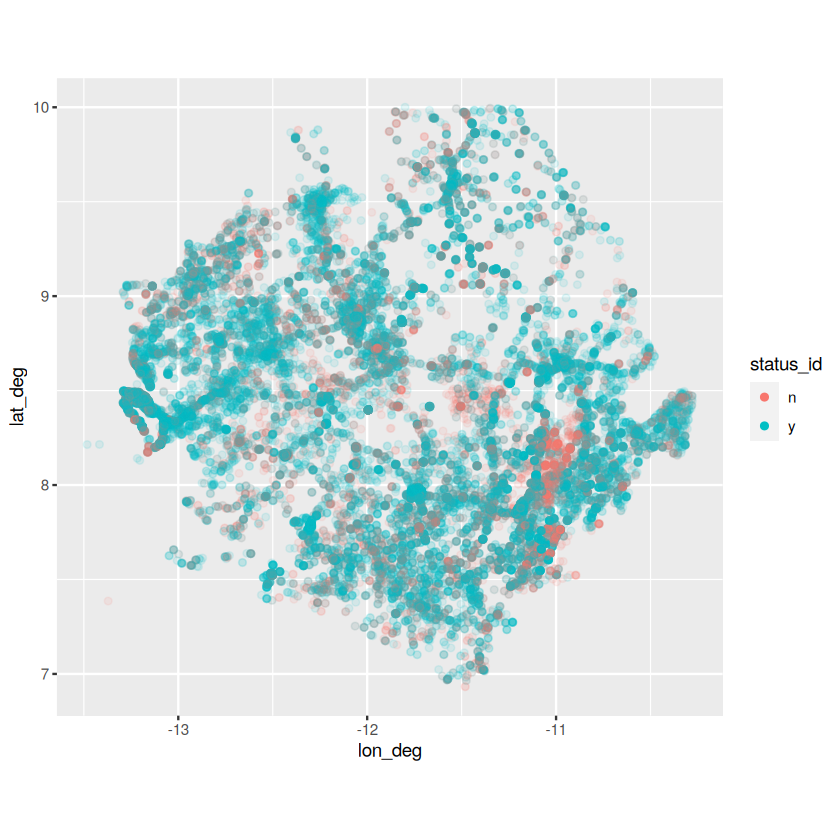

In [ ]:
water_raw %>%
  filter(
    country_name == "Sierra Leone",
    lat_deg > 0, lat_deg < 15, lon_deg < 0,
    status_id %in% c("y", "n")
  ) %>%
  ggplot(aes(lon_deg, lat_deg, color = status_id)) +
  geom_point(alpha = 0.1) +
  coord_fixed() +
  guides(color = guide_legend(override.aes = list(alpha = 1)))

## **Limpieza**

Igual que en regresión logística: se hace sobre el dataset entero, antes de dividir (filtrar filas, recodificar `pay`, sacar columnas que no sirven).

In [ ]:
water <- water_raw %>% #creamos nuevo objeto llamado water
  filter(
    country_name == "Sierra Leone",
    lat_deg > 0, lat_deg < 15, lon_deg < 0,
    status_id %in% c("y", "n")
  ) %>%
  mutate(pay = case_when(
    str_detect(pay, "^No") ~ "no",
    str_detect(pay, "^Yes") ~ "yes",
    is.na(pay) ~ pay,
    TRUE ~ "it's complicated"
  )) %>%
  select(-country_name, -status, -report_date) %>%
  mutate_if(is.character, as.factor)

glimpse(water)

Rows: 54,793
Columns: 10
$ row_id        <dbl> 252544, 36202, 34613, 36006, 36063, 36291, 34364, 34977,…
$ lat_deg       <dbl> 9.445763, 8.369090, 8.483420, 8.378530, 8.483860, 8.3853…
$ lon_deg       <dbl> -12.48694, -13.23060, -13.23500, -13.24050, -13.24310, -…
$ status_id     <fct> n, y, y, y, n, n, y, y, y, y, y, y, y, n, y, n, y, y, y,…
$ water_source  <fct> NA, NA, Surface Water (River/Stream/Lake/Pond/Dam), NA, …
$ water_tech    <fct> Hand Pump, Rope and Bucket, Hydram, Hydram, Hand Pump - …
$ facility_type <fct> NA, NA, No facilities, NA, NA, NA, Improved, Unimproved,…
$ install_year  <dbl> 1997, 2017, 2011, 2014, 1994, 2017, NA, 2003, 2017, 2016…
$ installer     <fct> NA, "Community", "Guma", "no", "private owner", "Communi…
$ pay           <fct> NA, yes, yes, yes, yes, yes, NA, yes, yes, yes, yes, yes…


## **División train/test y folds**

El split train/test es **el mismo** que en logística (misma semilla) → los resultados en test son comparables.

**Diferencia con logística:** SVM es mucho más lento de entrenar (el costo crece más o menos con el cuadrado de las filas) y acá no entrenamos 1 modelo sino **una grilla** de modelos × 5 folds.
Por eso el **grid search se hace sobre una submuestra estratificada del 15% de train** (~6.000 filas). Para *elegir* hiperparámetros alcanza; el modelo final (`last_fit`) sí se entrena con **todo** train.

In [ ]:
set.seed(123)
water_split <- initial_split(water, strata = status_id)
water_train <- training(water_split)
water_test <- testing(water_split)

# Submuestra de train SOLO para el grid search (mantiene la proporción de clases)
set.seed(234)
water_tune <- water_train %>%
  group_by(status_id) %>%
  slice_sample(prop = 0.15) %>%
  ungroup()

# 5 folds de validación cruzada sobre la submuestra
set.seed(345)
tune_folds <- vfold_cv(water_tune, v = 5, strata = status_id)
print(tune_folds)

#  5-fold cross-validation using stratification 
# A tibble: 5 x 2
  splits              id   
  <list>              <chr>
1 <split [4930/1233]> Fold1
2 <split [4930/1233]> Fold2
3 <split [4930/1233]> Fold3
4 <split [4930/1233]> Fold4
5 <split [4932/1231]> Fold5


In [ ]:
water_train %>% count(status_id)
water_test %>% count(status_id)
water_tune %>% count(status_id)

status_id,n
<fct>,<int>
n,10329
y,30765


status_id,n
<fct>,<int>
n,3444
y,10255


status_id,n
<fct>,<int>
n,1549
y,4614


## **La receta**

Igual que en logística **más dos pasos que SVM necesita**:

* `step_dummy()`: SVM trabaja con distancias/productos entre vectores numéricos, así que las categóricas pasan a columnas 0/1.
* `step_normalize()`: centra y escala (media 0, desvío 1). **Clave en SVM**: si una variable tiene valores grandes (ej. `install_year` ≈ 2000) domina la distancia y el kernel; además gamma solo tiene sentido si todas las variables están en la misma escala.

La receta se *define* con `water_train` como molde; las medias/desvíos se calculan dentro de cada fold (y en `last_fit` con train), nunca con test.

In [ ]:
svm_recipe <-
  recipe(formula = status_id ~ ., data = water_train) %>%   # status_id en función de todo lo demás
  update_role(row_id, new_role = "id") %>%                  # row_id es identificador: el modelo no lo usa
  step_unknown(all_nominal_predictors()) %>%                # NA en categóricas -> "unknown"
  step_other(all_nominal_predictors(), threshold = 0.03) %>% # categorías con < 3% -> "other"
  step_impute_linear(install_year) %>%                      # imputa install_year con un modelo lineal
  step_dummy(all_nominal_predictors()) %>%                  # NUEVO: categóricas -> columnas 0/1
  step_zv(all_predictors()) %>%                             # saca columnas constantes (varianza cero)
  step_normalize(all_numeric_predictors()) %>%              # NUEVO: media 0, desvío 1
  step_downsample(status_id)                                # balancea clases (solo se aplica en train)

## **El modelo**

Especificamos **tres modelos SVM, uno por kernel**. En lugar de fijar C y gamma ponemos `tune()`: le decimos a tidymodels *"este valor lo vas a buscar vos con la grilla"*.

* `cost` = **C**
* `rbf_sigma` = **gamma**
* `degree` = grado del polinomio (en el polinomial fijamos `scale_factor = 0.1` para no agrandar la grilla)

El motor es `kernlab`. Para tener probabilidades (necesarias para ROC/AUC) `kernlab` ajusta además una curva logística sobre los puntajes del SVM (*Platt scaling*).

In [ ]:
# Kernel lineal: solo C
svm_lineal_spec <- svm_linear(cost = tune()) %>%
  set_engine("kernlab") %>%
  set_mode("classification")

# Kernel RBF: C y gamma
svm_rbf_spec <- svm_rbf(cost = tune(), rbf_sigma = tune()) %>%
  set_engine("kernlab") %>%
  set_mode("classification")

# Kernel polinomial: C y grado
svm_poly_spec <- svm_poly(cost = tune(), degree = tune(), scale_factor = 0.1) %>%
  set_engine("kernlab") %>%
  set_mode("classification")

## **Workflow**

Misma receta, tres modelos → tres workflows.

In [ ]:
wf_lineal <- workflow() %>% add_recipe(svm_recipe) %>% add_model(svm_lineal_spec)
wf_rbf    <- workflow() %>% add_recipe(svm_recipe) %>% add_model(svm_rbf_spec)
wf_poly   <- workflow() %>% add_recipe(svm_recipe) %>% add_model(svm_poly_spec)

wf_rbf

══ Workflow ════════════════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: svm_rbf()

── Preprocessor ────────────────────────────────────────────────────────────────
7 Recipe Steps

• step_unknown()
• step_other()
• step_impute_linear()
• step_dummy()
• step_zv()
• step_normalize()
• step_downsample()

── Model ───────────────────────────────────────────────────────────────────────
Radial Basis Function Support Vector Machine Model Specification (classification)

Main Arguments:
  cost = tune()
  rbf_sigma = tune()

Computational engine: kernlab 


## **Grilla de hiperparámetros**

Los valores van en **escala logarítmica** (0.01, 0.1, 1, 10): lo que importa es el orden de magnitud, no 1 vs 1.2.

* Lineal: 4 valores de C → 4 modelos
* RBF: 3 C × 3 gamma → 9 modelos
* Polinomial: 2 C × 2 grados → 4 modelos

Total: 17 combinaciones × 5 folds = **85 entrenamientos**.

In [ ]:
grid_lineal <- tibble(cost = c(0.01, 0.1, 1, 10))

grid_rbf <- expand_grid(
  cost      = c(0.1, 1, 10),       # C
  rbf_sigma = c(0.001, 0.01, 0.1)  # gamma
)

grid_poly <- expand_grid(
  cost   = c(0.1, 1),
  degree = c(2, 3)
)

grid_rbf

cost,rbf_sigma
<dbl>,<dbl>
0.1,0.001
0.1,0.010
0.1,0.100
1.0,0.001
1.0,0.010
1.0,0.100
10.0,0.001
10.0,0.010
10.0,0.100


## **Entrenamiento con validación cruzada (grid search)**

En logística usamos `fit_resamples()` porque había **un solo** modelo. Acá usamos **`tune_grid()`**: hace lo mismo, pero **para cada fila de la grilla**.

Para cada combinación (ej. C = 1, gamma = 0.01):
1. entrena en 4 folds y evalúa en el fold que quedó afuera,
2. repite 5 veces,
3. promedia la métrica.

La combinación con mejor promedio es la elegida. **Test no se toca.**

In [ ]:
doParallel::registerDoParallel()

metricas <- metric_set(roc_auc, accuracy)
ctrl <- control_grid(save_pred = TRUE)

set.seed(7443)
res_lineal <- tune_grid(wf_lineal, resamples = tune_folds, grid = grid_lineal,
                        metrics = metricas, control = ctrl)

set.seed(7443)
res_rbf <- tune_grid(wf_rbf, resamples = tune_folds, grid = grid_rbf,
                     metrics = metricas, control = ctrl)

set.seed(7443)
res_poly <- tune_grid(wf_poly, resamples = tune_folds, grid = grid_poly,
                      metrics = metricas, control = ctrl)

## **Métricas de validación cruzada**

`collect_metrics()` da una fila por combinación y métrica: `mean` es el promedio en los 5 folds y `std_err` cuánto varía entre folds.

In [ ]:
res_rbf %>% collect_metrics()

cost,rbf_sigma,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
0.1,0.001,accuracy,binary,0.8508895,5,0.005300642,Preprocessor1_Model1
0.1,0.001,roc_auc,binary,0.8627212,5,0.007194710,Preprocessor1_Model1
0.1,0.010,accuracy,binary,0.8964812,5,0.004601852,Preprocessor1_Model2
0.1,0.010,roc_auc,binary,0.8673740,5,0.007941146,Preprocessor1_Model2
0.1,0.100,accuracy,binary,0.8640292,5,0.005043090,Preprocessor1_Model3
0.1,0.100,roc_auc,binary,0.8711035,5,0.008991516,Preprocessor1_Model3
1.0,0.001,accuracy,binary,0.8966434,5,0.004777448,Preprocessor1_Model4
1.0,0.001,roc_auc,binary,0.8732429,5,0.008383976,Preprocessor1_Model4
1.0,0.010,accuracy,binary,0.8958324,5,0.005914392,Preprocessor1_Model5


Gráfico de la grilla RBF: eje x = C, un color por gamma. Fijate cómo **gamma alto (0.1)** empeora la accuracy aunque suba C: es el sobreajuste del que habla la clase.

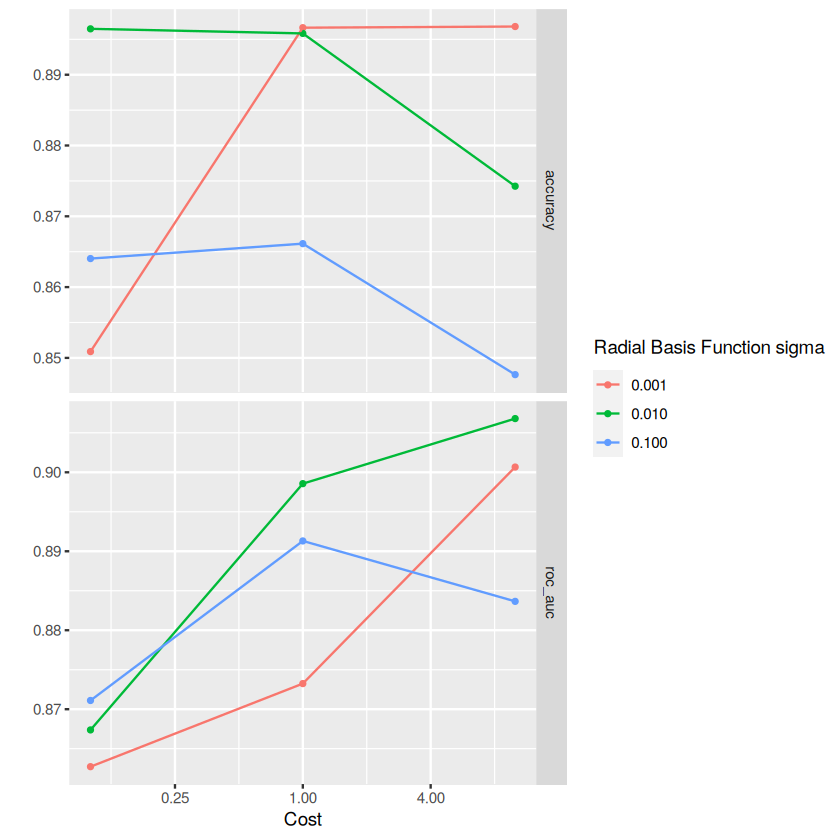

In [ ]:
autoplot(res_rbf)

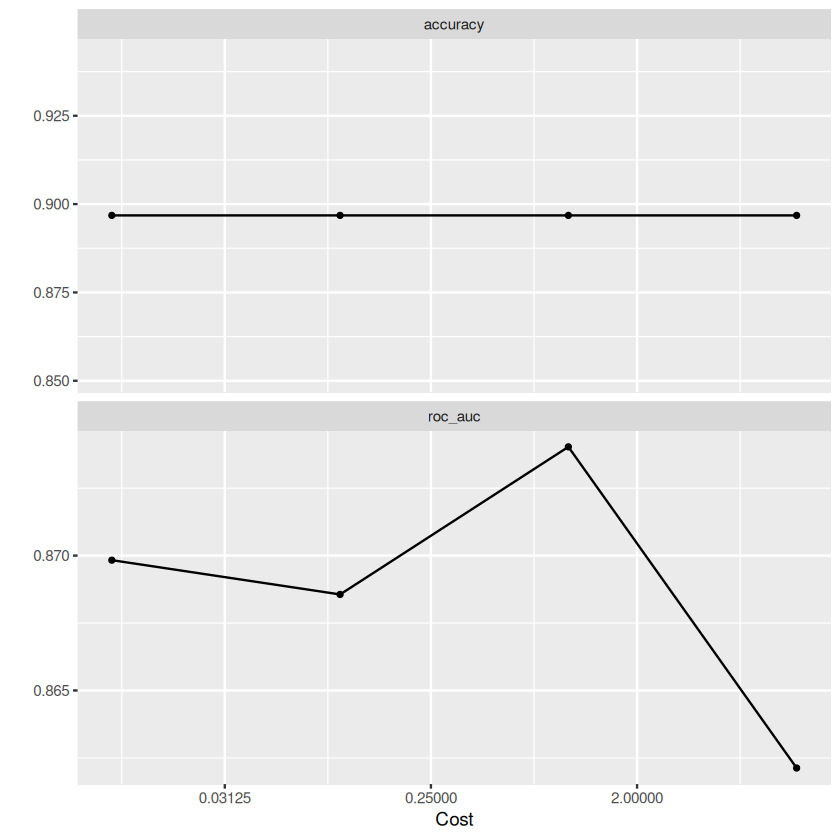

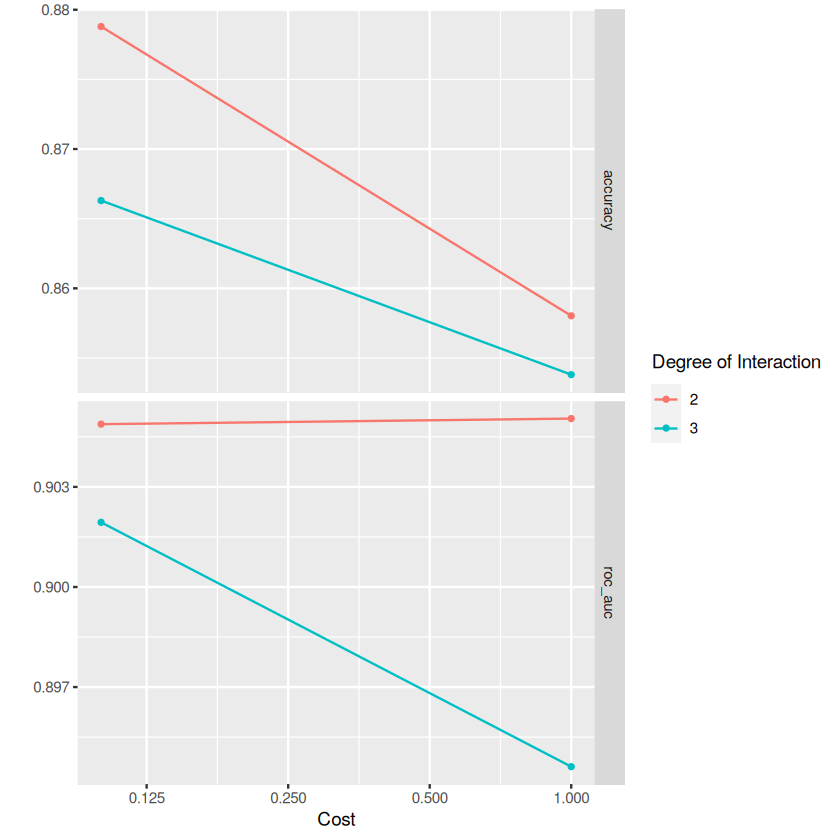

In [ ]:
autoplot(res_lineal)
autoplot(res_poly)

In [ ]:
# Las 3 mejores combinaciones del RBF según AUC
show_best(res_rbf, metric = "roc_auc", n = 3)

cost,rbf_sigma,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
10,0.010,roc_auc,binary,0.9068008,5,0.005854639,Preprocessor1_Model8
10,0.001,roc_auc,binary,0.9006632,5,0.008172877,Preprocessor1_Model7
1,0.010,roc_auc,binary,0.8985605,5,0.007759288,Preprocessor1_Model5


## **Comparación de kernels**

El mejor de cada kernel, ordenados por AUC promedio en CV. Elegimos por **roc_auc** (no accuracy) porque mide qué tan bien el modelo *ordena* los casos con cualquier umbral y es menos engañosa con clases desbalanceadas.

In [ ]:
comparacion <- bind_rows(
  show_best(res_lineal, metric = "roc_auc", n = 1) %>% mutate(kernel = "lineal"),
  show_best(res_rbf,    metric = "roc_auc", n = 1) %>% mutate(kernel = "rbf"),
  show_best(res_poly,   metric = "roc_auc", n = 1) %>% mutate(kernel = "polinomial")
) %>%
  select(kernel, cost, rbf_sigma, degree, mean, std_err) %>%
  arrange(desc(mean))

comparacion

kernel,cost,rbf_sigma,degree,mean,std_err
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
rbf,10,0.01,NA,0.9068008,0.005854639
polinomial,1,NA,2,0.9050474,0.005363493
lineal,1,NA,NA,0.8740328,0.008397078


## **Elegimos el mejor modelo**

* `mejor_kernel`: el primero de la tabla de arriba (se elige solo, no hay que tocar nada).
* `select_best()`: devuelve la combinación ganadora de hiperparámetros de ese kernel.
* `finalize_workflow()`: reemplaza los `tune()` del workflow por esos valores → queda un workflow "normal", como el de logística.

In [ ]:
resultados <- list(lineal = res_lineal, rbf = res_rbf, polinomial = res_poly)
flujos     <- list(lineal = wf_lineal,  rbf = wf_rbf,  polinomial = wf_poly)

mejor_kernel   <- comparacion$kernel[1]
mejores_params <- select_best(resultados[[mejor_kernel]], metric = "roc_auc")

final_wf <- finalize_workflow(flujos[[mejor_kernel]], mejores_params)

mejor_kernel
mejores_params
final_wf

[1] "rbf"

cost,rbf_sigma,.config
<dbl>,<dbl>,<chr>
10,0.01,Preprocessor1_Model8


══ Workflow ════════════════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: svm_rbf()

── Preprocessor ────────────────────────────────────────────────────────────────
7 Recipe Steps

• step_unknown()
• step_other()
• step_impute_linear()
• step_dummy()
• step_zv()
• step_normalize()
• step_downsample()

── Model ───────────────────────────────────────────────────────────────────────
Radial Basis Function Support Vector Machine Model Specification (classification)

Main Arguments:
  cost = 10
  rbf_sigma = 0.01

Computational engine: kernlab 


## **Ajuste final y evaluación en test**

Igual que en logística: `last_fit()` recibe el **split** → entrena el workflow final con **todo train** (no la submuestra) y evalúa **una sola vez** en test.

Puede tardar unos minutos: el SVM final se entrena con ~20.000 filas (train después del downsample).

**Por qué el `for`:** el *Platt scaling* de `kernlab` (lo que convierte el puntaje del SVM en probabilidad) usa una partición al azar interna y, con algunas semillas, su optimización no converge (*"line search fails"*) y el modelo queda sin probabilidades. Si pasa, se reintenta con otra semilla. El SVM en sí es el mismo; solo cambia esa calibración.

In [ ]:
for (semilla in 1:5) {
  set.seed(semilla)
  final_svm <- last_fit(final_wf, water_split, metrics = metricas)
  ok <- isTRUE(tryCatch(nrow(collect_metrics(final_svm)) > 0, error = function(e) FALSE))
  if (ok) break
  message("Falló el cálculo de probabilidades con semilla ", semilla, ", reintento...")
}

→ A | error:   $ operator is invalid for atomic vectors



There were issues with some computations   A: x1



There were issues with some computations   A: x1



Warning message:
“All models failed. Run `show_notes(.Last.tune.result)` for more information.”


Falló el cálculo de probabilidades con semilla 1, reintento...



## **Métricas en test**

In [ ]:
final_svm %>%
  collect_metrics()

.metric,.estimator,.estimate,.config
<chr>,<chr>,<dbl>,<chr>
accuracy,binary,0.8798452,Preprocessor1_Model1
roc_auc,binary,0.9202665,Preprocessor1_Model1


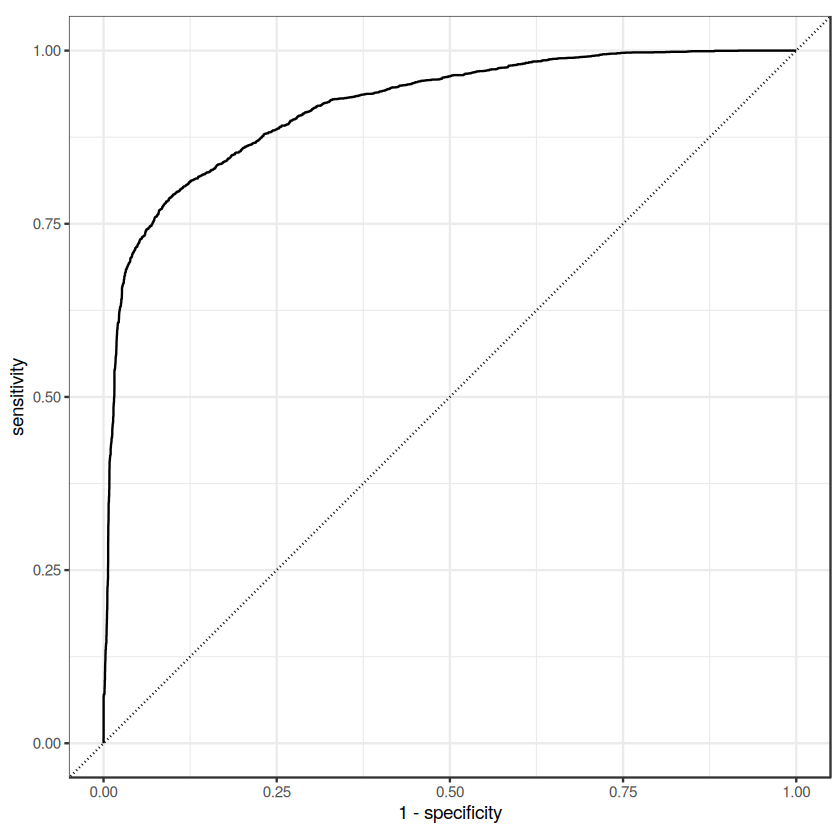

In [ ]:
# Curva ROC en test
final_svm %>%
  collect_predictions() %>%
  roc_curve(status_id, .pred_n) %>%
  autoplot()

## **Predicciones**

* `.pred_class`: clase predicha
* `.pred_n` / `.pred_y`: probabilidades (vía Platt scaling)
* `status_id`: clase real

Ojo: la **clase** la decide el SVM (de qué lado de la frontera cae el punto) y la **probabilidad** la estima Platt aparte. En casos muy cerca de la frontera pueden no coincidir (ej. `.pred_n` = 0.56 pero `.pred_class` = y). Es normal en SVM.

In [ ]:
final_svm %>%
  collect_predictions()

id,.pred_n,.pred_y,.row,.pred_class,status_id,.config
<chr>,<dbl>,<dbl>,<int>,<fct>,<fct>,<chr>
train/test split,0.43403096,0.56596904,2,y,y,Preprocessor1_Model1
train/test split,0.20556265,0.79443735,4,y,y,Preprocessor1_Model1
train/test split,0.10193941,0.89806059,8,y,y,Preprocessor1_Model1
train/test split,0.55651693,0.44348307,10,y,y,Preprocessor1_Model1
train/test split,0.19118007,0.80881993,11,y,y,Preprocessor1_Model1
train/test split,0.85861105,0.14138895,12,n,y,Preprocessor1_Model1
train/test split,0.13120680,0.86879320,13,y,y,Preprocessor1_Model1
train/test split,0.39645416,0.60354584,14,y,n,Preprocessor1_Model1
train/test split,0.19583852,0.80416148,17,y,y,Preprocessor1_Model1


## **Matriz de confusión**

In [ ]:
final_svm %>%
  collect_predictions() %>%
  conf_mat(status_id, .pred_class)

          Truth
Prediction    n    y
         n 2657  859
         y  787 9396

## **Comparación con regresión logística**

Mismo split de test para los dos modelos. Los valores de logística son los que obtuvimos en el notebook de Regresión Logística (accuracy 0.8728, AUC 0.9055).

In [ ]:
metricas_svm <- final_svm %>% collect_metrics()

tibble(
  modelo   = c("Regresión logística", paste0("SVM (", mejor_kernel, ")")),
  accuracy = c(0.8728, metricas_svm$.estimate[metricas_svm$.metric == "accuracy"]),
  roc_auc  = c(0.9055, metricas_svm$.estimate[metricas_svm$.metric == "roc_auc"])
)

modelo,accuracy,roc_auc
<chr>,<dbl>,<dbl>
Regresión logística,0.8728000,0.9055000
SVM (rbf),0.8798452,0.9202665


## **Conclusiones**

* **Kernel:** el lineal queda claramente abajo en AUC; RBF y polinomial capturan relaciones no lineales (por ejemplo, la ubicación lat/lon, que en el mapa forma zonas, no una línea recta).
* **C y gamma:** gamma alto (0.1) sobreajusta (cae la accuracy); el mejor RBF combina **gamma bajo/medio** con C más alto. Las diferencias entre las mejores combinaciones son chicas (mirar `std_err`): ante empate conviene la más simple (C y gamma bajos).
* **CV + grid search** eligió los hiperparámetros sin mirar test; test se usó **una sola vez**, al final.
* **SVM vs logística:** SVM mejora un poco en test, a cambio de mucho más tiempo de cómputo y de un modelo menos interpretable (la logística da coeficientes; el SVM con RBF no).
* Para afinar más: grilla más fina alrededor del mejor punto (ej. C entre 3 y 30, gamma entre 0.003 y 0.03), o tunear sobre una submuestra más grande.